<a href="https://colab.research.google.com/github/Divya-DataAnalystPortfolio/SMS-Spam-Detection-Using-Supervised-Machine-Learning/blob/main/SupervisedLearning_Largedataset_SMS_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset source: UCI Machine Learning Repository — SMS Spam Collection.

# **1. Load the dataset**

In [1]:
# 1. Download dataset directly into google colab
import pandas as pd
import zipfile
import urllib.request

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_spam_collection.zip")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [2]:
# 2. Extract the dataset
with zipfile.ZipFile("sms_spam_collection.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
# 3. Load the dataset into Pandas
df = pd.read_csv(
    "sms_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["Label", "Message"]
)

print(df.head())

  Label                                            Message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


# **2. Explore the Dataset**

In [4]:
df.shape

(5572, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Label    5572 non-null   object
 1   Message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [6]:
df["Label"].value_counts()

,count
Label,
ham,4825
spam,747


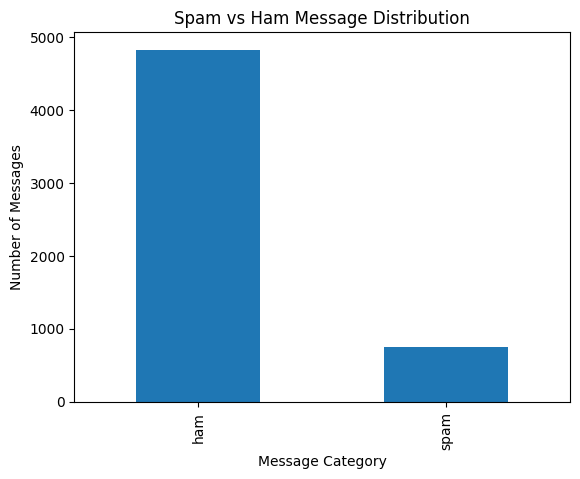

In [7]:
# Visualization the distribution
import matplotlib.pyplot as plt

df["Label"].value_counts().plot(kind="bar")

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

# **3 — Data Cleaning and Preprocessing.**






In [12]:
# Check missing values
df.isnull().sum()

,0
Label,0
Message,0


In [9]:
# check duplicates
df.duplicated().sum()

np.int64(403)

In [10]:
# Remove duplicate records
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (5169, 2)


In [11]:
# Check labels
df["Label"].unique()

array(['ham', 'spam'], dtype=object)

In [13]:
# Convert labels into numerical values
df["Label"] = df["Label"].map({
    "ham": 0,
    "spam": 1
})

print(df.head())

   Label                                            Message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...


# **4 — Text Preprocessing and Feature Extraction.**

Understand the problem
Consider these two messages:
- "Congratulations! You won a FREE prize!!!"
- "Congratulations you won a free prize"
They communicate almost the same information, but the text contains differences in capitalisation and punctuation.

We want to prepare text consistently before converting it into numerical features.

In [14]:
# Convert messages to lowercase
df["Message"] = df["Message"].str.lower()

print(df["Message"].head())

0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: Message, dtype: object


In [16]:
# Remove punctuation and special characters
import re

def clean_text(text):
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    return text

df["Message"] = df["Message"].apply(clean_text)

print(df["Message"].head())

0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in 2 a wkly comp to win fa cup fina...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: Message, dtype: object


In [17]:
# Convert text into numerical features
# Now we'll use TF-IDF (Term Frequency–Inverse Document Frequency).
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df["Message"])

print(X.shape)

(5169, 9541)


In [18]:
# Prepare the target variable
# We already converted our labels into 0 and 1.

# Let's store them in y

y = df["Label"]

print(y.head())

0    0
1    0
2    1
3    0
4    0
Name: Label, dtype: int64


In [19]:
print(X.shape)
print(y.shape)

(5169, 9541)
(5169,)


# **5 — Split the dataset into training and testing data**

In [20]:
# Import the function
from sklearn.model_selection import train_test_split

Code	              Purpose
1. X	              -         Input features
2. y	              -    Correct labels
3. test_size=0.2    -   Reserves 20% for testing
4. random_state=42	-    Makes the split reproducible
5. stratify=y	      -  Preserves the approximate Spam/Ham proportions

In [21]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
# Check the split
print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training input: (4135, 9541)
Testing input: (1034, 9541)
Training labels: (4135,)
Testing labels: (1034,)


# **6 — Train the model using Naive Bayes**

What is Naive Bayes?

Naive Bayes is a Machine Learning classification algorithm based on probability.


In [24]:
# Import the algorithm
from sklearn.naive_bayes import MultinomialNB

In [25]:
# Create the model
model = MultinomialNB()

In [26]:
# Train the model
model.fit(X_train, y_train)

MultinomialNB()

# **7 — Make predictions using the trained model**

In [27]:
# Create new SMS messages
new_messages = [
    "Congratulations! You won a free cash prize",
    "Hey, are we meeting tomorrow?",
    "Claim your lottery reward now"
]

In [28]:
# Convert the messages into numerical features
new_messages_vectorized = vectorizer.transform(new_messages)

In [29]:
# Predict the categories
predictions = model.predict(new_messages_vectorized)

print(predictions)

[1 0 1]


In [31]:
# Display readable predictions
for message, prediction in zip(new_messages, predictions):

    if prediction == 1:
        print(message, "→ Spam")
    else:
        print(message, "→ Ham")

Congratulations! You won a free cash prize → Spam
Hey, are we meeting tomorrow? → Ham
Claim your lottery reward now → Spam


# **8 — Evaluate the model**

In [32]:
# Generate predictions for testing data
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [33]:
# Calculate accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 94.97098646034816 %


In [34]:
#Generate a classification report
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       903
        Spam       1.00      0.60      0.75       131

    accuracy                           0.95      1034
   macro avg       0.97      0.80      0.86      1034
weighted avg       0.95      0.95      0.94      1034



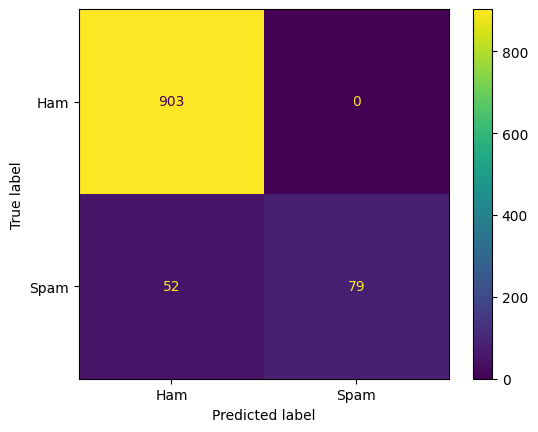

In [35]:
# Create a confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot()
plt.show()